# Hybrid Clinic KPI Analysis: virtual vs in-person primary care

**Business question.** A network of six primary care clinics runs a hybrid model: video, audio-only and in-person visits.
How does virtual care compare with in-person care on **access, attendance, productivity and revenue**, and where should clinic managers act?

> **Data note.** All clinic, provider, patient and visit data are **synthetic**: they come from the seeded generator `src/generate_synthetic.py` and describe no real patients or organizations.
> National context comes from the public [CMS Medicare Telehealth Trends](https://data.cms.gov/summary-statistics-on-use-and-payments/medicare-medicaid-service-type-reports/medicare-telehealth-trends) file.

The notebook reads the SQLite database built by `python run_all.py`. Every number in the text is computed in the cells below.

In [1]:
import sqlite3, sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from findings import compute

con = sqlite3.connect(ROOT / "data" / "processed" / "clinic_kpi.db")
sql = lambda q: pd.read_sql_query(q, con)
F = compute(ROOT / "data" / "processed" / "clinic_kpi.db")

COLORS = {"in_person": "#0b3954", "video": "#087e8b", "audio": "#f2a541", "fallback": "#e4572e"}
LABEL = {"in_person": "In-person", "video": "Video", "audio": "Audio-only", "fallback": "Video→audio\nfallback"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6ecf0", "axes.axisbelow": True, "font.size": 10})
pctfmt = mtick.PercentFormatter(1.0, decimals=None)

sql("""SELECT COUNT(*) AS appointments, COUNT(DISTINCT patient_id) AS patients, COUNT(DISTINCT provider_id) AS providers,
       COUNT(DISTINCT clinic_id) AS clinics, MIN(appt_date) AS first_visit, MAX(appt_date) AS last_visit FROM appointments""")

,appointments,patients,providers,clinics,first_visit,last_visit
0,100155,14939,18,6,2024-01-01,2025-12-31


## 0. National context (CMS): virtual care has settled into a stable share
CMS reports the share of telehealth-eligible Medicare beneficiaries who used telehealth in each quarter. Use spiked in 2020 and then **levelled off well above the pre-pandemic baseline**, so hybrid care is a lasting operating model and worth managing with KPIs. Rural beneficiaries consistently use less telehealth than urban ones.

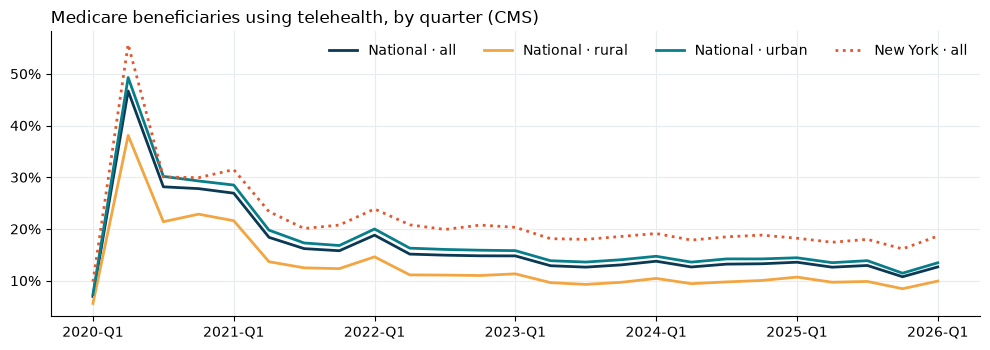

Peak **46.7%** in 2020 Q2; latest **12.7%** in 2026 Q1 (rural 9.9% vs urban 13.5%). In the synthetic network, virtual visits were **26.8%** of completed visits in 2024 and **30.1%** in 2025. That is a share of *visits*, not of *beneficiaries*, so the two series are not directly comparable.

In [2]:
cms = pd.read_csv(ROOT / "data" / "external" / "cms_telehealth_national.csv")
cms = cms[(cms.dimension == "rurality") & (cms.quarter != "Overall")].copy()
cms["period"] = cms.year.astype(str) + "-Q" + cms.quarter.astype(str)
fig, ax = plt.subplots(figsize=(10, 3.6))
for (geo, seg), color, ls in [(("National", "All"), "#0b3954", "-"), (("National", "Rural"), "#f2a541", "-"),
                              (("National", "Urban"), "#087e8b", "-"), (("New York", "All"), "#e4572e", ":")]:
    s = cms[(cms.geography == geo) & (cms.segment == seg)].sort_values(["year", "quarter"])
    ax.plot(s.period, s.pct_using_telehealth, color=color, ls=ls, lw=2, label=f"{geo} · {seg.lower()}")
ax.yaxis.set_major_formatter(pctfmt); ax.set_xticks(range(0, len(s), 4)); ax.set_xticklabels(s.period.iloc[::4])
ax.set_title("Medicare beneficiaries using telehealth, by quarter (CMS)", loc="left"); ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.show()
display(Markdown(f"Peak **{F['cms_peak_pct']:.1%}** in {F['cms_peak_label']}; latest **{F['cms_latest_all']:.1%}** in {F['cms_latest_label']} "
                 f"(rural {F['cms_latest_rural']:.1%} vs urban {F['cms_latest_urban']:.1%}). In the synthetic network, virtual visits were "
                 f"**{F['network_virtual_share_2024']:.1%}** of completed visits in 2024 and **{F['network_virtual_share_2025']:.1%}** in 2025. "
                 "That is a share of *visits*, not of *beneficiaries*, so the two series are not directly comparable."))

## 1. Access: virtual visits are available much sooner

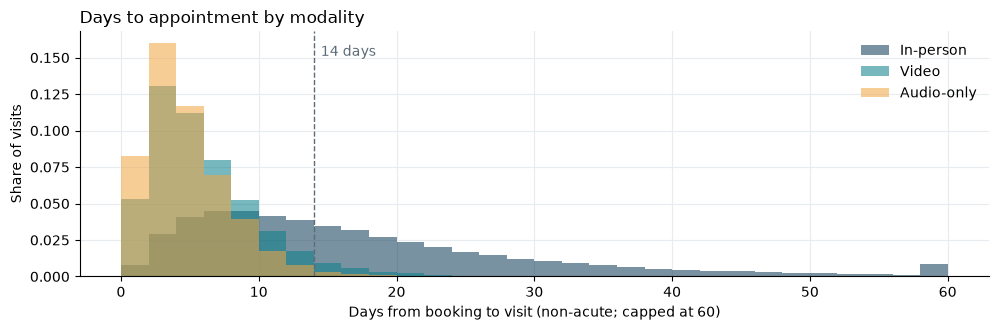

modality_scheduled,audio,in_person,video
clinic_name,,,
Cedar Ridge Family Health,4,14,5
Eastbrook Internal Medicine,3,12,4
Harborside Family Medicine,3,12,4
Maple Grove Primary Care,3,12,4
Pine Hollow Community Health,4,13,5
Riverbend Primary Care,4,21,6


In [3]:
lead = sql("""SELECT modality_scheduled AS modality, lead_days FROM appointments WHERE visit_type <> 'acute'""")
fig, ax = plt.subplots(figsize=(10, 3.4))
for m in ["in_person", "video", "audio"]:
    ax.hist(lead[lead.modality == m].lead_days.clip(upper=60), bins=range(0, 62, 2), density=True, alpha=.55, color=COLORS[m], label=LABEL[m])
ax.axvline(14, color="#5c6b78", ls="--", lw=1); ax.text(14.5, ax.get_ylim()[1] * .9, "14 days", color="#5c6b78")
ax.set_xlabel("Days from booking to visit (non-acute; capped at 60)"); ax.set_ylabel("Share of visits"); ax.legend(frameon=False)
ax.set_title("Days to appointment by modality", loc="left"); plt.tight_layout(); plt.show()
pd.read_csv(ROOT / "reports" / "kpi" / "days_to_appointment.csv").pivot(index="clinic_name", columns="modality_scheduled", values="median_lead_days")

## 2. Attendance: fewer no-shows for virtual visits, even at the same lead time

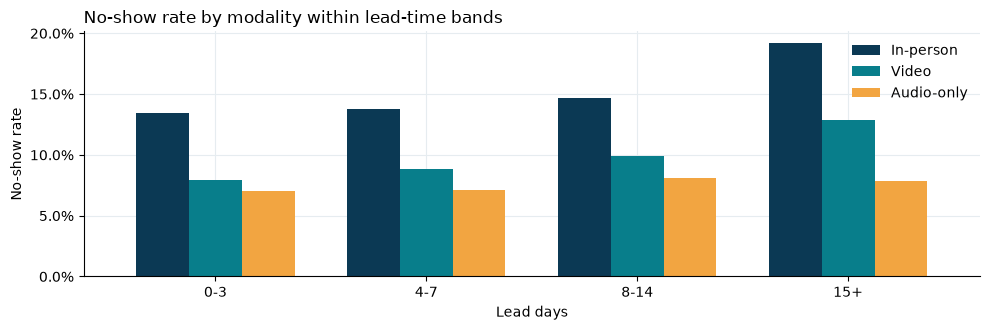

Overall no-show rate: in-person **15.9%**, video **8.6%**, audio-only **7.2%**. The gap holds within every lead-time band, so it is not only because virtual visits are booked sooner. No-shows also rise with lead time.

In [4]:
ns = sql("""SELECT modality_scheduled AS modality,
       CASE WHEN lead_days <= 3 THEN '0-3' WHEN lead_days <= 7 THEN '4-7' WHEN lead_days <= 14 THEN '8-14' ELSE '15+' END AS lead_bucket,
       1.0 * SUM(status = 'no_show') / SUM(status <> 'cancelled') AS no_show_rate, COUNT(*) AS n
FROM appointments GROUP BY 1, 2""")
order = ["0-3", "4-7", "8-14", "15+"]
piv = ns.pivot(index="lead_bucket", columns="modality", values="no_show_rate").loc[order, ["in_person", "video", "audio"]]
ax = piv.plot.bar(figsize=(10, 3.4), color=[COLORS[c] for c in piv.columns], rot=0, width=.75)
ax.yaxis.set_major_formatter(pctfmt); ax.set_xlabel("Lead days"); ax.set_ylabel("No-show rate")
ax.legend([LABEL[c] for c in piv.columns], frameon=False); ax.set_title("No-show rate by modality within lead-time bands", loc="left")
plt.tight_layout(); plt.show()
display(Markdown(f"Overall no-show rate: in-person **{F['no_show_in_person']:.1%}**, video **{F['no_show_video']:.1%}**, audio-only **{F['no_show_audio']:.1%}**. "
                 "The gap holds within every lead-time band, so it is not only because virtual visits are booked sooner. No-shows also rise with lead time."))

## 3. Clinic performance: Riverbend (C05) lags on access, attendance and utilization

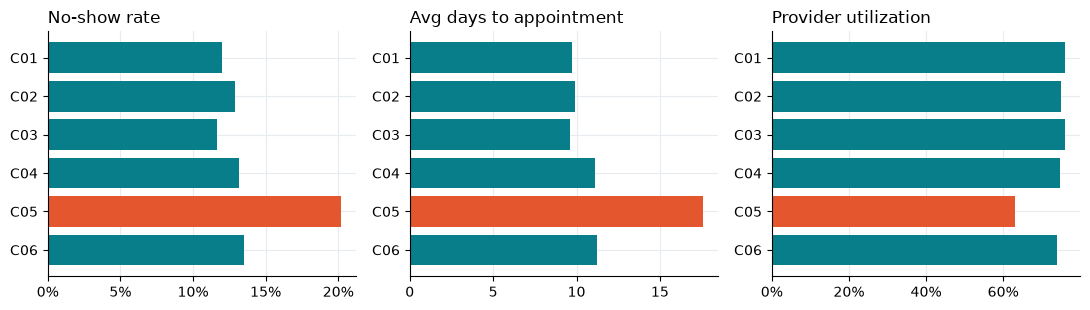

C05 no-show **20.2%** vs **12.6%** peer average; in-person non-acute lead time **25.4** vs **15.3** days; utilization **63.0%** vs **75.2%**. At peer utilization C05 would complete about **1,119 more visits per year**.

clinic_id,clinic_name,setting,scheduled,no_show_rate,avg_lead_days,virtual_share,denial_rate,gross_charges,utilization
C01,Harborside Family Medicine,Urban,17100,12.0%,9.700000,30.3%,5.9%,"$2,047,220",76.1%
C02,Maple Grove Primary Care,Suburban,16848,12.9%,9.900000,26.7%,6.3%,"$1,976,120",75.1%
C03,Eastbrook Internal Medicine,Urban,16941,11.6%,9.600000,32.1%,6.0%,"$2,018,763",76.1%
C04,Pine Hollow Community Health,Rural,16716,13.2%,11.100000,29.0%,6.5%,"$1,919,069",74.8%
C05,Riverbend Primary Care,Suburban,15654,20.2%,17.600000,23.2%,9.4%,"$1,682,216",63.0%
C06,Cedar Ridge Family Health,Rural,16896,13.5%,11.200000,28.2%,6.3%,"$1,926,277",73.9%


In [5]:
score = pd.read_csv(ROOT / "reports" / "kpi" / "clinic_scorecard.csv")
util = pd.read_csv(ROOT / "reports" / "kpi" / "provider_utilization.csv")
cu = util.groupby("clinic_id")[["completed", "slots"]].sum(); cu["utilization"] = cu.completed / cu.slots
score = score.merge(cu.utilization.reset_index(), on="clinic_id").sort_values("clinic_id")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title, fmt in zip(axes, ["no_show_rate", "avg_lead_days", "utilization"],
                               ["No-show rate", "Avg days to appointment", "Provider utilization"], [pctfmt, None, pctfmt]):
    ax.barh(score.clinic_id, score[col], color=["#e4572e" if c == "C05" else "#087e8b" for c in score.clinic_id])
    ax.set_title(title, loc="left"); ax.invert_yaxis()
    if fmt: ax.xaxis.set_major_formatter(fmt)
plt.tight_layout(); plt.show()
display(Markdown(f"C05 no-show **{F['c05_no_show']:.1%}** vs **{F['peer_no_show']:.1%}** peer average; in-person non-acute lead time **{F['c05_ip_lead']:.1f}** vs "
                 f"**{F['peer_ip_lead']:.1f}** days; utilization **{F['c05_util']:.1%}** vs **{F['peer_util']:.1%}**. At peer utilization C05 would complete about "
                 f"**{F['c05_lost_visits_per_year']:,.0f} more visits per year**."))
score.style.format({"no_show_rate": "{:.1%}", "virtual_share": "{:.1%}", "denial_rate": "{:.1%}", "utilization": "{:.1%}", "gross_charges": "${:,.0f}"}).hide(axis="index")

## 4. Equity: rural and older patients face a digital gap

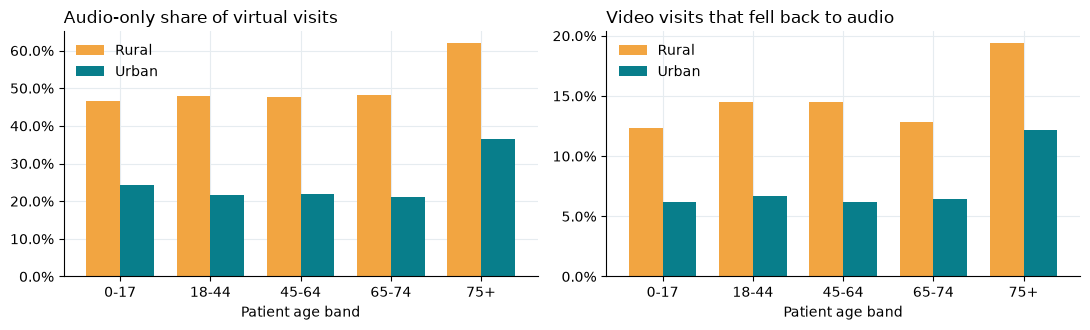

Audio-only makes up **50.2%** of rural virtual visits vs **24.6%** urban. **14.6%** of rural video visits drop to audio vs **7.3%** urban, and the 75+ band is highest in both.

In [6]:
eq = pd.read_csv(ROOT / "reports" / "kpi" / "equity_gaps.csv")
fb = pd.read_csv(ROOT / "reports" / "kpi" / "video_fallback.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, df, col, title in [(axes[0], eq, "audio_share_of_virtual", "Audio-only share of virtual visits"),
                           (axes[1], fb, "fallback_rate", "Video visits that fell back to audio")]:
    p = df.pivot(index="age_band", columns="rurality", values=col)
    p.plot.bar(ax=ax, color=["#f2a541", "#087e8b"], rot=0, width=.75); ax.yaxis.set_major_formatter(pctfmt)
    ax.set_title(title, loc="left"); ax.set_xlabel("Patient age band"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(Markdown(f"Audio-only makes up **{F['rural_audio_share']:.1%}** of rural virtual visits vs **{F['urban_audio_share']:.1%}** urban. "
                 f"**{F['rural_fallback']:.1%}** of rural video visits drop to audio vs **{F['urban_fallback']:.1%}** urban, and the 75+ band is highest in both."))

## 5. Revenue integrity: video→audio fallbacks are denied most often and need more in-person follow-up

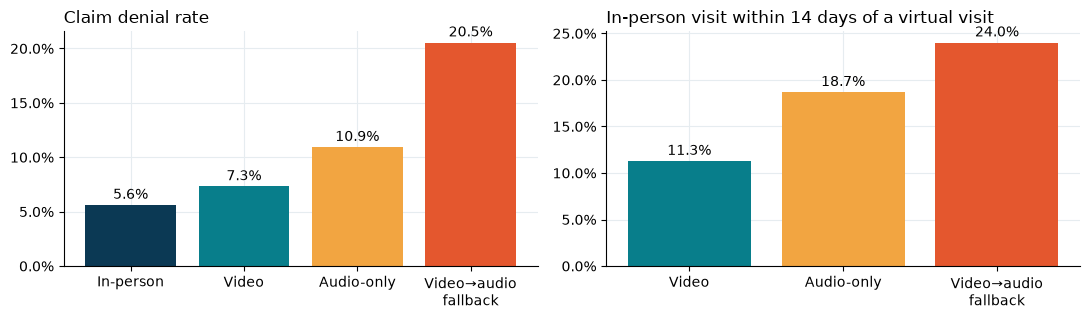

,claims,denial_rate,avg_charge,denied_charges
key,,,,
in_person,57428,0.0562,156.38,504139.0
video,13795,0.0733,131.71,133279.0
audio,7615,0.1094,85.81,71362.0
fallback,1382,0.2055,86.08,24507.0


In [7]:
den = pd.read_csv(ROOT / "reports" / "kpi" / "denial_rate.csv")
den["key"] = den.apply(lambda r: "fallback" if "fallback" in r.path else r.modality_delivered, axis=1)
den = den.set_index("key").loc[["in_person", "video", "audio", "fallback"]]
fu = pd.Series({"video": F["followup_video"], "audio": F["followup_audio"], "fallback": F["followup_fallback"]})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].bar([LABEL[k] for k in den.index], den.denial_rate, color=[COLORS[k] for k in den.index])
axes[0].set_title("Claim denial rate", loc="left"); axes[0].yaxis.set_major_formatter(pctfmt)
axes[1].bar([LABEL[k] for k in fu.index], fu.values, color=[COLORS[k] for k in fu.index])
axes[1].set_title("In-person visit within 14 days of a virtual visit", loc="left"); axes[1].yaxis.set_major_formatter(pctfmt)
for ax in axes:
    for c in ax.containers: ax.bar_label(c, labels=[f"{v:.1%}" for v in c.datavalues], padding=2)
plt.tight_layout(); plt.show()
den[["claims", "denial_rate", "avg_charge", "denied_charges"]]

## Key findings and recommended actions

In [8]:
display(Markdown("\n".join(f"{i}. **{h['title']}.** {h['text']}  \n   *Action:* {h['action']}" for i, h in enumerate(F["headlines"], 1))))

1. **Virtual visits open access faster.** Non-acute virtual visits are booked 5.1 days out on average vs 17.0 days in person; 46.9% of in-person bookings wait more than 14 days vs 2.6% of virtual.  
   *Action:* Offer a virtual slot first for chronic follow-ups when the next in-person slot is >14 days out.
2. **Virtual visits cut no-shows roughly in half.** No-show rate is 15.9% in person vs 8.6% video and 7.2% audio-only.  
   *Action:* Target in-person reminder outreach at long-lead bookings, where no-shows concentrate.
3. **Riverbend (C05) is the clinic to fix first.** No-show 20.2% vs 12.6% peer average; in-person non-acute lead time 25.4 vs 15.3 days; provider utilization 63.0% vs 75.2% — about 1,119 completed visits a year below peers.  
   *Action:* Open template slots and add virtual capacity at C05; review its scheduling workflow.
4. **Rural patients hit a digital gap.** Audio-only is 50.2% of rural virtual visits vs 24.6% urban, and 14.6% of rural video visits fail over to audio vs 7.3% urban.  
   *Action:* Run pre-visit tech checks / device support for rural and 75+ patients before video visits.
5. **Video→audio fallbacks leak revenue.** Fallback visits are denied 20.5% of the time vs 7.3% for video and 5.6% in person ($24,507 denied), and 24.0% need an in-person visit within 14 days.  
   *Action:* Add a coding check that updates modality/modifier when a video visit drops to audio.

## Limitations
- The clinic data is **synthetic**. Its patterns were designed to be realistic and explainable, but the effect sizes are assumptions, not estimates from real operations.
- The comparisons are descriptive. Visit type, lead time and patient mix differ by modality, and section 2 controls only for lead time.
- The 14-day in-person follow-up is a flag on each virtual visit, not a link to a separate encounter.
- The CMS series measures beneficiaries who used telehealth, while the network series measures visits. Use CMS only as directional context.

In [9]:
con.close()